### Importacion de bibliotecas iniciales

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import plotly.express as px
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

### Carga de base de datos procesada

In [ ]:
datos_url= '/content/dataset_churn_procesado_para_ml.csv'
df= pd.read_csv(datos_url)
df.head()

,Attrition_Flag,Customer_Age,Months_Inactive_12_mon,Contacts_Count_12_mon,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Low_Relationship_Count,Gender_M,Card_Category_Gold,Card_Category_Platinum,Card_Category_Silver
0,0,45,1,3,1.625,0.061,0,1,0,0,0
1,0,49,1,2,3.714,0.105,0,0,0,0,0
2,0,51,1,0,2.333,0.000,0,1,0,0,0
3,0,40,4,1,2.333,0.760,1,0,0,0,0
4,0,40,1,0,2.500,0.000,0,1,0,0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Attrition_Flag          10127 non-null  int64  
 1   Customer_Age            10127 non-null  int64  
 2   Months_Inactive_12_mon  10127 non-null  int64  
 3   Contacts_Count_12_mon   10127 non-null  int64  
 4   Total_Ct_Chng_Q4_Q1     10127 non-null  float64
 5   Avg_Utilization_Ratio   10127 non-null  float64
 6   Low_Relationship_Count  10127 non-null  int64  
 7   Gender_M                10127 non-null  int64  
 8   Card_Category_Gold      10127 non-null  int64  
 9   Card_Category_Platinum  10127 non-null  int64  
 10  Card_Category_Silver    10127 non-null  int64  
dtypes: float64(2), int64(9)
memory usage: 870.4 KB


### Revisión de correlacion inicial

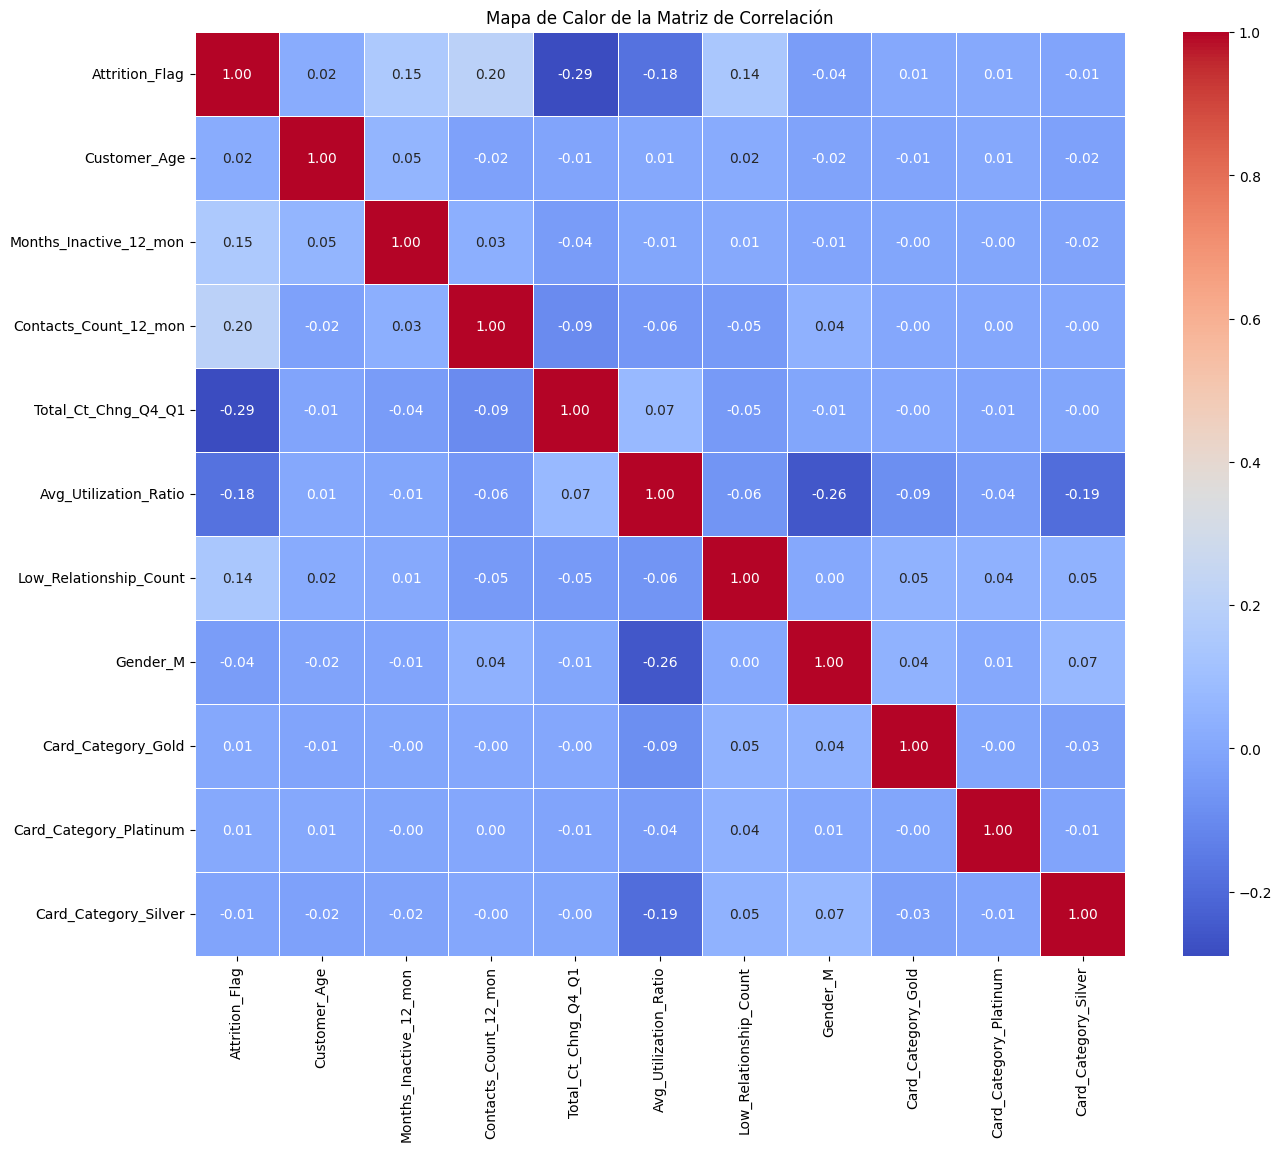

In [ ]:
datos_corr = df.copy()
correlation_matrix = datos_corr.corr()

plt.figure(figsize=(15, 12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Mapa de Calor de la Matriz de Correlación')
plt.show()

Las variables más correlacionadas con Attrition_Flag son:

- Total_Ct_Chng_Q4_Q1 (-0.29), sugiere que un menor cambio en el total de contactos entre los trimestres Q4 y Q1 se asocia con una mayor tasa de abandono.
- Contacts_Count_12_mon (0.20) indica que más contactos en 12 meses están relacionados con una mayor tasa de abandono.
- Avg_Utilization_Ratio (0.18): Indica que un mayor promedio de la tasa de utilización de la tarjeta está relacionado con una mayor tasa de abandono.
- Months_Inactive_12_mon (0.15): Sugiere que un mayor número de meses inactivos en los últimos 12 meses está relacionado con una mayor tasa de abandono.

*NOTA*
- **Programa de educación financiera:** Este es el pilar fundamental. Si la falta de educación financiera es la causa subyacente, dotar a los clientes de herramientas y conocimientos para gestionar mejor sus finanzas podría ser la estrategia de retención más sostenible y valiosa. Podría reducir tanto la alta utilización como la inactividad por miedo o desconocimiento.
- **Crédito especial para ayuda financiera:** Esto podría ser un salvavidas para clientes en apuros y una fuerte señal de que la institución se preocupa por su bienestar. Podría fortalecer la lealtad y reducir la probabilidad de abandono por razones económicas.
- **Opciones de inversión:** Ofrecer vías para mejorar su situación financiera a largo plazo es una excelente idea. No solo aborda la causa raíz, sino que también puede convertir a un cliente en riesgo en uno más comprometido y rentable a futuro.

Consideraciones adicionales:

- Segmentación: los clientes con altos Avg_Utilization_Ratio y - Months_Inactive_12_mon podrían estar pasando por una dificultad temporal, o por una falta estructural de educación.
- Medición: ¿Disminuy la tasa de abandono en este segmento? ¿Mejora su Avg_Utilization_Ratio? ¿Participan en los programas de educación?

### Separacion de variables

In [ ]:
X = df.drop('Attrition_Flag', axis=1)
y = df['Attrition_Flag']
X

,Customer_Age,Months_Inactive_12_mon,Contacts_Count_12_mon,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Low_Relationship_Count,Gender_M,Card_Category_Gold,Card_Category_Platinum,Card_Category_Silver
0,45,1,3,1.625,0.061,0,1,0,0,0
1,49,1,2,3.714,0.105,0,0,0,0,0
2,51,1,0,2.333,0.000,0,1,0,0,0
3,40,4,1,2.333,0.760,1,0,0,0,0
4,40,1,0,2.500,0.000,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...
10122,50,2,3,0.857,0.462,1,1,0,0,0
10123,41,2,3,0.683,0.511,0,1,0,0,0
10124,44,3,4,0.818,0.000,0,0,0,0,0
10125,30,3,3,0.722,0.000,0,1,0,0,0


In [ ]:
y = y.rename('Canceled_Yes')
y

,Canceled_Yes
0,0
1,0
2,0
3,0
4,0
...,...
10122,0
10123,1
10124,1
10125,1


### Creacion de conjunto de entrenamiento y conjunto de prueba

In [ ]:
from sklearn.model_selection import train_test_split

# Dividir los datos en conjuntos de entrenamiento y prueba (75% entrenamiento, 25% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=67, stratify=y)

In [ ]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((7595, 10), (2532, 10), (7595,), (2532,))

### Creacion de modelo Baseline

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Inicializar y entrenar el DummyClassifier
modelo_dummy  = DummyClassifier(strategy="most_frequent")
modelo_dummy.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
y_pred_dummy = modelo_dummy.predict(X_test)


Rendimiento del Modelo Baseline (DummyClassifier): 83.9258 %


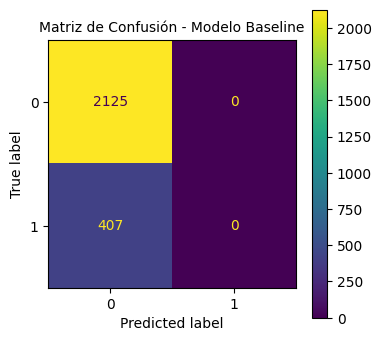

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Rendimiento del modelo baseline
print(f"Rendimiento del Modelo Baseline (DummyClassifier): {round(modelo_dummy.score(X_test, y_test)*100,4)} %")

# Usar ConfusionMatrixDisplay para graficar la matriz de confusión
fig, ax = plt.subplots(figsize=(4, 4)) # Crear figura y ejes con tamaño deseado
ConfusionMatrixDisplay.from_estimator(modelo_dummy, X_test, y_test, ax=ax) # Pasar los ejes a la función
plt.title('Matriz de Confusión - Modelo Baseline', fontsize=10) # Título al gráfico
plt.show() # Mostrar el gráfico

In [ ]:
print("\nReporte de Clasificación:")
# Agregar zero_division=0 para manejar la división por cero y eliminar el warning
print(classification_report(y_test, y_pred_dummy, zero_division=0))


Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.84      1.00      0.91      2125
           1       0.00      0.00      0.00       407

    accuracy                           0.84      2532
   macro avg       0.42      0.50      0.46      2532
weighted avg       0.70      0.84      0.77      2532



De acuerdo al reporte de clasificación, el modelo base predice correctamente que el 83.92% de los clientes no abandonarán (clase 0). Sin embargo para la clase 1 el modelo tuvo una precision del 0%, es decir, no identifica a ningún cliente que realmente abandona, con un recall de 0, donde el support indica que 407 clientes realmente abandonaron, (falsos negativos). En conclusion este modelo no sirve para detectar el abandono.

### Modelo Random Forest

Rendimiento del Modelo Random Forest: 86.6509 %


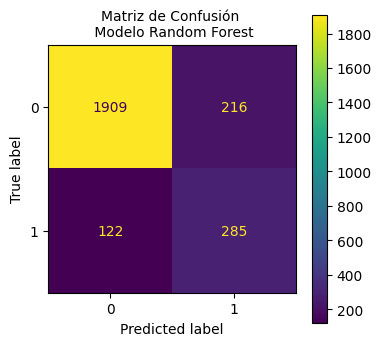

In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
# Inicializar y entrenar el modelo Random Forest
modelo_rdm_forest = RandomForestClassifier(class_weight= 'balanced',
                                           max_depth= 10,
                                           min_samples_leaf= 2,
                                           min_samples_split= 5,
                                           n_estimators= 200,
                                           random_state=58)
modelo_rdm_forest.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
y_pred_rf = modelo_rdm_forest.predict(X_test)

# Rendimiento del modelo Arbol
print(f"Rendimiento del Modelo Random Forest: {round(modelo_rdm_forest.score(X_test, y_test)*100,4)} %")

fig, ax = plt.subplots(figsize=(4, 4)) # Crear figura y ejes con tamaño deseado
ConfusionMatrixDisplay.from_estimator(modelo_rdm_forest, X_test, y_test, ax=ax) # Pasar los ejes a la función
plt.title('Matriz de Confusión \n Modelo Random Forest', fontsize=10) # Título del gráfico
plt.show() # Mostrar el gráfico

In [ ]:
print("\nReporte de Clasificación del Modelo Random Forest:")
print(classification_report(y_test, y_pred_rf, zero_division=0))


Reporte de Clasificación del Modelo Random Forest:
              precision    recall  f1-score   support

           0       0.94      0.90      0.92      2125
           1       0.57      0.70      0.63       407

    accuracy                           0.87      2532
   macro avg       0.75      0.80      0.77      2532
weighted avg       0.88      0.87      0.87      2532



Este modelo muestra un rendimiento del 87% de precisión (accuracy). Predice con una alta fiabilidad a los clientes que no abandonarán (clase 0), con una precisión del 94% y un recall del 90%. Este modelo   tiene un recall del 70% pa la clase 1, lo que significa que detecta 7 de cada 10 clientes que van a abandonar, con una precisión del 57%. En conclusión, este modelo es mucho más útil para detectar el abandono que el modelo base, aunque todavía hay margen de mejora en la precisión para la clase 1.

### Optimizacion de Random Forest

In [ ]:
from imblearn.over_sampling import SMOTE

# Initialize SMOTE
smote = SMOTE(random_state=58)

# Apply SMOTE to the training data
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f"Shape of X_train before SMOTE: {X_train.shape}")
print(f"Shape of y_train before SMOTE: {y_train.shape}")
print(f"Shape of X_train after SMOTE: {X_train_smote.shape}")
print(f"Shape of y_train after SMOTE: {y_train_smote.shape}")

print("\nClass distribution in y_train before SMOTE:")
print(y_train.value_counts())
print("\nClass distribution in y_train_smote after SMOTE:")
print(y_train_smote.value_counts())

Shape of X_train before SMOTE: (7595, 10)
Shape of y_train before SMOTE: (7595,)
Shape of X_train after SMOTE: (12750, 10)
Shape of y_train after SMOTE: (12750,)

Class distribution in y_train before SMOTE:
Canceled_Yes
0    6375
1    1220
Name: count, dtype: int64

Class distribution in y_train_smote after SMOTE:
Canceled_Yes
0    6375
1    6375
Name: count, dtype: int64


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Initialize RandomForestClassifier with balanced class weight and random state
rf_classifier_smote = RandomForestClassifier(class_weight='balanced', random_state=58)

# Define the parameter grid for GridSearchCV
param_grid_rf_smote = {
    'n_estimators': [300, 500],
    'max_depth': [30],
    'min_samples_leaf': [1],
    'min_samples_split': [1, 2]
}

# Set up GridSearchCV to optimize for recall of the positive class (class 1)
# Using 'recall' as scoring metric to focus on minority class recall
grid_search_rf_smote = GridSearchCV(estimator=rf_classifier_smote,
                                  param_grid=param_grid_rf_smote,
                                  scoring='recall',
                                  cv=5, # Using 5-fold cross-validation
                                  verbose=2,
                                  n_jobs=-1) # Use all available cores

# Fit GridSearchCV to the SMOTE-balanced training data
grid_search_rf_smote.fit(X_train_smote, y_train_smote)

# Print the best parameters and best score found
print("Mejores parámetros encontrados (RandomForest con SMOTE):", grid_search_rf_smote.best_params_)
print("Mejor recall (clase minoritaria) en validación cruzada (RandomForest con SMOTE):", grid_search_rf_smote.best_score_)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Mejores parámetros encontrados (RandomForest con SMOTE): {'max_depth': 30, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 500}
Mejor recall (clase minoritaria) en validación cruzada (RandomForest con SMOTE): 0.8710588235294118


Rendimiento del Modelo RandomForest Optimizado con SMOTE:
Accuracy: 0.8250
Precision (Clase 1): 0.4695
Recall (Clase 1): 0.6806
F1-Score (Clase 1): 0.5557
AUC: 0.8398

Reporte de Clasificación (RandomForest Optimizado con SMOTE):
              precision    recall  f1-score   support

           0       0.93      0.85      0.89      2125
           1       0.47      0.68      0.56       407

    accuracy                           0.83      2532
   macro avg       0.70      0.77      0.72      2532
weighted avg       0.86      0.83      0.84      2532



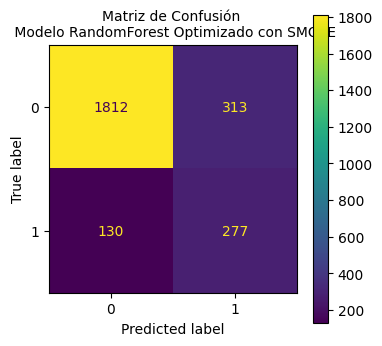

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Obtener el mejor estimador del RandomForestClassifier optimizado con SMOTE
modelo_rf_smote_optimizado = grid_search_rf_smote.best_estimator_

# 2. Realizar predicciones sobre el conjunto de prueba
y_pred_rf_smote = modelo_rf_smote_optimizado.predict(X_test)

# 3. Obtener las probabilidades de predicción para la clase positiva
y_pred_proba_rf_smote = modelo_rf_smote_optimizado.predict_proba(X_test)[:, 1]

# 4-8. Calcular las métricas
accuracy_rf_smote = accuracy_score(y_test, y_pred_rf_smote)
precision_rf_smote = precision_score(y_test, y_pred_rf_smote, average='binary', zero_division=0)
recall_rf_smote = recall_score(y_test, y_pred_rf_smote, average='binary', zero_division=0)
f1_rf_smote = f1_score(y_test, y_pred_rf_smote, average='binary', zero_division=0)
auc_rf_smote = roc_auc_score(y_test, y_pred_proba_rf_smote)

# 9. Imprimir todas las métricas calculadas
print("Rendimiento del Modelo RandomForest Optimizado con SMOTE:")
print(f"Accuracy: {accuracy_rf_smote:.4f}")
print(f"Precision (Clase 1): {precision_rf_smote:.4f}")
print(f"Recall (Clase 1): {recall_rf_smote:.4f}")
print(f"F1-Score (Clase 1): {f1_rf_smote:.4f}")
print(f"AUC: {auc_rf_smote:.4f}")

# 10. Generar y mostrar un reporte de clasificación
print("\nReporte de Clasificación (RandomForest Optimizado con SMOTE):")
print(classification_report(y_test, y_pred_rf_smote, zero_division=0))

# 11. Crear y mostrar la matriz de confusión
fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay.from_estimator(modelo_rf_smote_optimizado, X_test, y_test, ax=ax)
plt.title('Matriz de Confusión \n Modelo RandomForest Optimizado con SMOTE', fontsize=10)
plt.show()

### Modelo Light GBM Classifier

[LightGBM] [Info] Number of positive: 1220, number of negative: 6375
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004093 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 575
[LightGBM] [Info] Number of data points in the train set: 7595, number of used features: 9
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
Rendimiento del Modelo LightGBM: 84.7946 %

Reporte de Clasificación (LightGBM):
              precision    recall  f1-score   support

           0       0.95      0.87      0.91      2125
           1       0.52      0.74      0.61       407

    accuracy                           0.85      2532
   macro avg       0.73      0.81      0.76      2532
weighted avg       0.88      0.85      0.86      2532



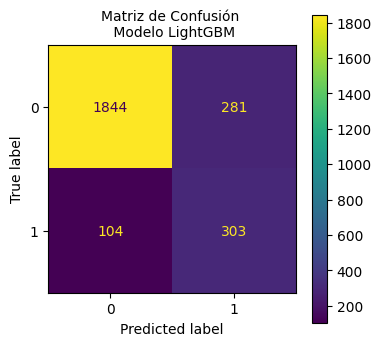

In [ ]:
from lightgbm import LGBMClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Initialize and train the LGBMClassifier model
modelo_lgbm = LGBMClassifier(class_weight='balanced', random_state=58)
modelo_lgbm.fit(X_train, y_train)

# Make predictions on the test set
y_pred_lgbm = modelo_lgbm.predict(X_test)

# Rendimiento del modelo LightGBM
print(f"Rendimiento del Modelo LightGBM: {round(modelo_lgbm.score(X_test, y_test)*100,4)} %")

# Generate and display the classification report
print("\nReporte de Clasificación (LightGBM):")
print(classification_report(y_test, y_pred_lgbm))

# Create and display the confusion matrix
fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay.from_estimator(modelo_lgbm, X_test, y_test, ax=ax)
plt.title('Matriz de Confusión \n Modelo LightGBM', fontsize=10)
plt.show()

### Optimización de Light GBM Classifier


In [ ]:
from sklearn.model_selection import GridSearchCV
from lightgbm import LGBMClassifier

# Initialize LGBMClassifier with balanced class weight and random state
lgbm = LGBMClassifier(class_weight='balanced', random_state=58)

# Mejores parámetros encontrados: {'learning_rate': 0.05, 'max_depth': 10,
# 'min_child_samples': 20, 'n_estimators': 100, 'num_leaves': 20, 'subsample': 0.7}

# Define the parameter grid for GridSearchCV
param_grid = {
    'n_estimators': [25, 50, 100],
    'learning_rate': [0.001, 0.005],
    'num_leaves': [5, 10],
    'max_depth': [10, 15],
    'min_child_samples': [3, 5, 10],
    'subsample': [0.05, 0.2]
}

# Set up GridSearchCV to optimize for recall of the positive class (class 1)
# Using 'recall' as scoring metric to focus on minority class recall
grid_search = GridSearchCV(estimator=lgbm,
                           param_grid=param_grid,
                           scoring='recall',
                           cv=3, # Using 3-fold cross-validation
                           verbose=2,
                           n_jobs=-1) # Use all available cores

# Fit GridSearchCV to the training data
grid_search.fit(X_train, y_train)

# Print the best parameters and best score found
print("Mejores parámetros encontrados:", grid_search.best_params_)
print("Mejor recall (clase minoritaria) en validación cruzada:", grid_search.best_score_)

Fitting 3 folds for each of 144 candidates, totalling 432 fits
[LightGBM] [Info] Number of positive: 1220, number of negative: 6375
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001233 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 577
[LightGBM] [Info] Number of data points in the train set: 7595, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
Mejores parámetros encontrados: {'learning_rate': 0.005, 'max_depth': 10, 'min_child_samples': 3, 'n_estimators': 50, 'num_leaves': 5, 'subsample': 0.05}
Mejor recall (clase minoritaria) en validación cruzada: 0.7893433065846859


Rendimiento del Modelo LightGBM Optimizado: 71.4455 %

Reporte de Clasificación (LightGBM Optimizado):
              precision    recall  f1-score   support

           0       0.95      0.70      0.80      2125
           1       0.34      0.80      0.47       407

    accuracy                           0.71      2532
   macro avg       0.64      0.75      0.64      2532
weighted avg       0.85      0.71      0.75      2532



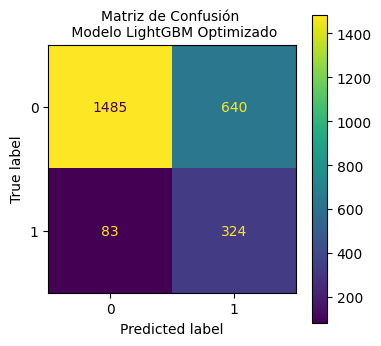


AUC (LightGBM Optimizado): 0.8241162017632606


In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt

# Get the best LightGBM model from grid_search
modelo_lgbm_optimizado = grid_search.best_estimator_

# Make predictions on the test set
y_pred_lgbm_optimizado = modelo_lgbm_optimizado.predict(X_test)
y_pred_proba_lgbm_optimizado = modelo_lgbm_optimizado.predict_proba(X_test)[:, 1]

# Print the accuracy of the optimized LightGBM model
print(f"Rendimiento del Modelo LightGBM Optimizado: {round(modelo_lgbm_optimizado.score(X_test, y_test)*100,4)} %")

# Generate and display the classification report
print("\nReporte de Clasificación (LightGBM Optimizado):")
print(classification_report(y_test, y_pred_lgbm_optimizado))

# Create and display the confusion matrix
fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay.from_estimator(modelo_lgbm_optimizado, X_test, y_test, ax=ax)
plt.title('Matriz de Confusión \n Modelo LightGBM Optimizado', fontsize=10)
plt.show()

# Calculate and display the AUC
auc_lgbm_optimizado = roc_auc_score(y_test, y_pred_proba_lgbm_optimizado)
print(f"\nAUC (LightGBM Optimizado): {auc_lgbm_optimizado}")

## Modelo: XGBoost Classifier

In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    random_state=42,
    scale_pos_weight=y_train.value_counts()[0] / y_train.value_counts()[1]
)

xgb_model.fit(X_train, y_train)





XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=None, num_parallel_tree=None, ...)

##Curva ROC

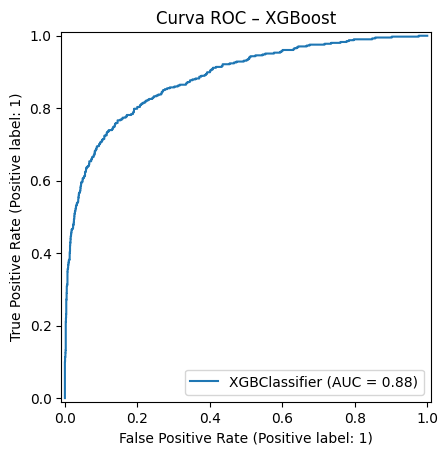

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(
    xgb_model,
    X_test,
    y_test
)

plt.title("Curva ROC – XGBoost")
plt.show()


##Matriz de confusion

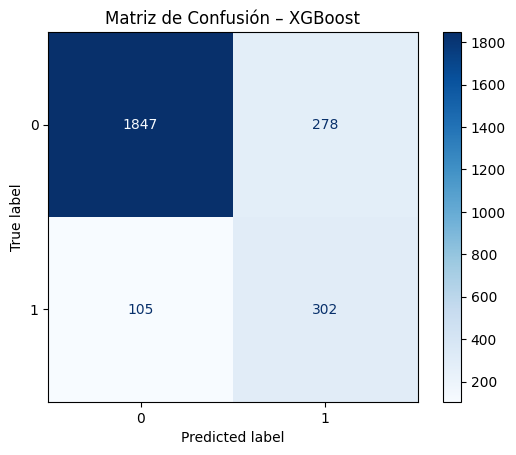

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    xgb_model,
    X_test,
    y_test,
    cmap='Blues'
)

plt.title("Matriz de Confusión – XGBoost")
plt.show()


##Importancia de variables

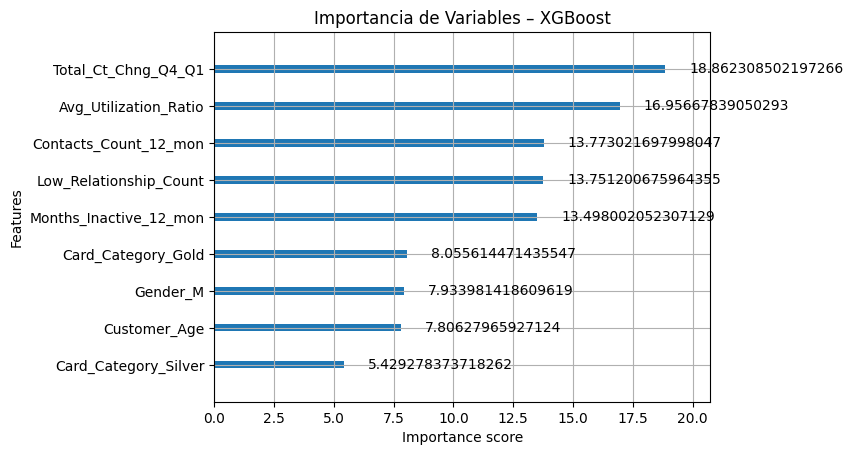

In [ ]:
from xgboost import plot_importance

plot_importance(
    xgb_model,
    max_num_features=15,
    importance_type='gain'
)

plt.title("Importancia de Variables – XGBoost")
plt.show()


## Modelo optimizado XGBosst Classifier

In [ ]:
from sklearn.model_selection import GridSearchCV

xgb_base = XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    random_state=42,
    scale_pos_weight=y_train.value_counts()[0] / y_train.value_counts()[1]
)

param_grid_xgb = {
    'n_estimators': [200, 400],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.03, 0.05],
    'subsample': [0.7, 0.8],
    'colsample_bytree': [0.7, 0.8]
}

grid_xgb = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid_xgb,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    verbose=2
)

grid_xgb.fit(X_train, y_train)

modelo_xgb_optimizado = grid_xgb.best_estimator_


Fitting 5 folds for each of 48 candidates, totalling 240 fits


In [ ]:
y_pred_xgb = xgb_model.predict(X_test)
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

auc_xgb = roc_auc_score(y_test, y_proba_xgb)

print("XGBoost Classifier")
print(classification_report(y_test, y_pred_xgb))
print(f"AUC: {auc_xgb:.4f}")


XGBoost Classifier
              precision    recall  f1-score   support

           0       0.95      0.87      0.91      2125
           1       0.52      0.74      0.61       407

    accuracy                           0.85      2532
   macro avg       0.73      0.81      0.76      2532
weighted avg       0.88      0.85      0.86      2532

AUC: 0.8840


## Predicciones y Medi

In [ ]:

y_pred_xgb_opt = modelo_xgb_optimizado.predict(X_test)
y_proba_xgb_opt = modelo_xgb_optimizado.predict_proba(X_test)[:, 1]

auc_xgb_opt = roc_auc_score(y_test, y_proba_xgb_opt)

print("Optimized XGBoost Classifier")
print(classification_report(y_test, y_pred_xgb_opt))
print(f"AUC: {auc_xgb_opt:.4f}")



Optimized XGBoost Classifier
              precision    recall  f1-score   support

           0       0.95      0.84      0.89      2125
           1       0.48      0.78      0.59       407

    accuracy                           0.83      2532
   macro avg       0.71      0.81      0.74      2532
weighted avg       0.88      0.83      0.84      2532

AUC: 0.8841


### Comparacion de modelos

In [ ]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Lista de modelos y sus predicciones
modelos_preds = [
    ('DummyClassifier', modelo_dummy, y_pred_dummy),
    ('RandomForestClassifier', modelo_rdm_forest, y_pred_rf),
    ('Optimized RandomForestClassifier', modelo_rf_smote_optimizado, y_pred_rf_smote),
    ('LightGBM Classifier', modelo_lgbm, y_pred_lgbm),
    ('Optimized LightGBM Classifier', modelo_lgbm_optimizado, y_pred_lgbm_optimizado),
    ('XGBoost Classifier', xgb_model, y_pred_xgb),
    ('Optimized XGBoost Classifier', modelo_xgb_optimizado, y_pred_xgb_opt)

]

# Diccionario para almacenar las métricas
resumen_metricas = {}

for nombre, modelo, y_pred in modelos_preds:
    # Calcular métricas comunes
    accuracy = accuracy_score(y_test, y_pred)
    # Usar average='binary' y zero_division=0 para clasificación binaria y manejar warnings
    precision = precision_score(y_test, y_pred, average='binary', zero_division=0)
    recall = recall_score(y_test, y_pred, average='binary', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='binary', zero_division=0)

    # Calcular AUC si el modelo lo soporta (predict_proba)
    auc = None
    if hasattr(modelo, 'predict_proba'):
        y_pred_proba = modelo.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, y_pred_proba)

    resumen_metricas[nombre] = {
        'Accuracy': accuracy,
        'Precision (Clase 1)': precision,
        'Recall (Clase 1)': recall,
        'F1-Score (Clase 1)': f1,
        'AUC': auc
    }



# Crear un DataFrame con el resumen de métricas
df_resumen = pd.DataFrame.from_dict(resumen_metricas, orient='index')

print("Resumen de Métricas de los Modelos:")
df_resumen_ordenado = df_resumen.sort_values(
    by='AUC', ascending=False
)

df_resumen_ordenado

Resumen de Métricas de los Modelos:


,Accuracy,Precision (Clase 1),Recall (Clase 1),F1-Score (Clase 1),AUC
Optimized XGBoost Classifier,0.827804,0.478064,0.776413,0.591760,0.884121
XGBoost Classifier,0.848736,0.520690,0.742015,0.611955,0.883959
RandomForestClassifier,0.866509,0.568862,0.700246,0.627753,0.879055
LightGBM Classifier,0.847946,0.518836,0.744472,0.611504,0.878204
Optimized RandomForestClassifier,0.825039,0.469492,0.680590,0.555667,0.839807
Optimized LightGBM Classifier,0.714455,0.336100,0.796069,0.472648,0.824116
DummyClassifier,0.839258,0.000000,0.000000,0.000000,0.500000


### Seleccion de modelos champion

In [ ]:
import pickle
modelo_champion1 = 'Light GBM optimizado'
modelo_champion2 = 'Random Forest'
modelo_champion3 = 'XG Boost Classifier'

# Guardar modelo champion1 LightGBM optimizado
with open('modelo_champion1.pkl', 'wb') as archivo:
    pickle.dump(modelo_lgbm_optimizado, archivo)


# Guardar modelo champion2 Random Forest
with open('modelo_champion2.pkl', 'wb') as archivo:
    pickle.dump(modelo_rdm_forest, archivo)

# Guardar modelo champion2 Random Forest
with open('modelo_champion3.pkl', 'wb') as archivo:
    pickle.dump(xgb_model, archivo)

### Identificacion de clientes de alto riesgo

In [ ]:
# 1. Elimina la variable objetivo del DataFrame para predicción
df_features = df.drop('Attrition_Flag', axis=1)

# 2. Determinar la probabilidad de cancelación
# Modelo Campion 1 = modelo_lgbm_optimizado
prob_cancel = modelo_lgbm_optimizado.predict_proba(df_features)

# 3. Extraer probabilidad de Cancelaciones (Attrition_Flag = 1)
df['Prob_Cancel'] = prob_cancel[:, 1]

# Visualizar el DF con la nueva columna de probabilidad de cancelacion
print("DataFrame con Prob_Cancel:")
display(df.head())


DataFrame con Prob_Cancel:


,Attrition_Flag,Customer_Age,Months_Inactive_12_mon,Contacts_Count_12_mon,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Low_Relationship_Count,Gender_M,Card_Category_Gold,Card_Category_Platinum,Card_Category_Silver,Prob_Cancel
0,0,45,1,3,1.625,0.061,0,1,0,0,0,0.437754
1,0,49,1,2,3.714,0.105,0,0,0,0,0,0.435355
2,0,51,1,0,2.333,0.000,0,1,0,0,0,0.500475
3,0,40,4,1,2.333,0.760,1,0,0,0,0,0.435355
4,0,40,1,0,2.500,0.000,0,1,0,0,0,0.500475


### Funcion para buscar clientes de forma masiva

In [ ]:
def analisis_gral_alto_riesgo(probabilidad_objetivo):
    """
    Filtra el DataFrame principal `df` para identificar clientes con una probabilidad de cancelación
    superior a la especificada.

    Args:
        probabilidad_objetivo (float): Umbral de probabilidad para considerar a un cliente como de alto riesgo.

    Returns:
        pd.DataFrame: Un DataFrame que contiene a los clientes cuya probabilidad de cacncelación
                      supera el umbral especificado.
    """
    # Asegurarse de que 'Prob_Cancel' existe en el DataFrame global
    if 'Prob_Cancel' not in globals()['df'].columns:
        print("Error: La columna 'Prob_Cancel' no se encuentra en el DataFrame 'df'.")
        return pd.DataFrame()

    # Filtrar el DataFrame df global
    df_alto_riesgo = globals()['df'][globals()['df']['Prob_Cancel'] > probabilidad_objetivo].copy()

    return df_alto_riesgo

print("Funcion 'analisis_gral_alto_riesgo' definida correctamente.")

Funcion 'analisis_gral_alto_riesgo' definida correctamente.


### Funcion para establecer probabilidad, para realizar busqueda masiva

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# 1. Entrada de texto para ingresar la probabilidad objetivo para filtrar
input_prob = widgets.FloatText(
    value=0.7,
    description='Probabilidad:',
    min=0.0,
    max=1.0,
    step=0.05,
    disabled=False
)

# 3. Boton
button_filtro = widgets.Button(
    description='Filtrar Clientes de Alto Riesgo',
    disabled=False,
    button_style='success', # 'success', 'info', 'warning', 'danger' or ''
    tooltip='Haz clic para filtrar clientes',
    icon='filter'
)

# 4. Visualización de resutltados
output_widget_filtrado = widgets.Output()

# 5. Funcion para filtrar reusltados
def funcion_filtrar(b):
    with output_widget_filtrado:
        clear_output()
        umbral = input_prob.value
        print(f"Filtrando clientes con probabilidad de churn > {umbral:.2f}...")
        df_alto_riesgo = analisis_gral_alto_riesgo(umbral)
        if not df_alto_riesgo.empty:
            print(f"Se encontraron {len(df_alto_riesgo)} clientes con probabilidad de churn > {umbral:.2f}:")
            display(df_alto_riesgo.head()) # Muesta solo encabezado, cambiar para mostrar df total

            print(f"Forma del DataFrame de clientes de alto riesgo: {df_alto_riesgo.shape}")
        else:
            print("No se encontraron clientes que cumplan con el umbral especificado.")

print("Widget interactivo para filtrar clientes de alto riesgo implementado.\n")

# 6. Ejecutar funcion luego de presionar el boton
button_filtro.on_click(funcion_filtrar)

# 7. Visualizacion de resultados
display(input_prob, button_filtro, output_widget_filtrado)



Widget interactivo para filtrar clientes de alto riesgo implementado.



FloatText(value=0.7, description='Probabilidad:', step=0.05)

Button(button_style='success', description='Filtrar Clientes de Alto Riesgo', icon='filter', style=ButtonStyle…

Output()

### Funcion para buscar cliente por ID

In [ ]:
from sklearn.tree import _tree

def detalle_arbol_simple(modelo_arbol, nombres_caracteristicas, datos_muestra):
    """
    Extrae los detalles del camino de decisión para una única muestra de un DecisionTreeClassifier.
    Devuelve una lista de diccionarios, cada uno describiendo una división o el nodo hoja.

    Args:
        modelo_arbol (DecisionTreeClassifier): El modelo de Árbol de Decisión entrenado.
        nombres_caracteristicas (list): Una lista de los nombres de las características usadas por el modelo.
        datos_muestra (pd.DataFrame o pd.Series): Los datos de la única muestra a analizar.
    """
    arbol_ = modelo_arbol.tree_
    indicador_nodo = modelo_arbol.decision_path(datos_muestra)
    id_hoja = modelo_arbol.apply(datos_muestra)

    detalles_camino = []
    for id_nodo in indicador_nodo.indices:
        if id_hoja[0] == id_nodo:
            # Este es el nodo hoja
            total_muestras = arbol_.value[id_nodo].sum()
            # Manejar casos donde class_weight='balanced' podría hacer que total_muestras sea 0 en un nodo
            prob_churn_en_nodo = arbol_.value[id_nodo][0, 1] / total_muestras if total_muestras > 0 else 0
            detalles_camino.append({'type': 'leaf', 'churn_prob': prob_churn_en_nodo})
            break

        indice_caracteristica = arbol_.feature[id_nodo]
        umbral = arbol_.threshold[id_nodo]
        nombre_caracteristica = nombres_caracteristicas[indice_caracteristica]
        valor_cliente = datos_muestra.iloc[0, indice_caracteristica]

        operador = "<=" if valor_cliente <= umbral else ">"
        detalles_camino.append({
            'type': 'split',
            'feature': nombre_caracteristica,
            'operator': operador,
            'threshold': umbral,
            'customer_value': valor_cliente
        })
    return detalles_camino

def detalle_random_forest(modelo_rf, nombres_caracteristicas, datos_muestra):
    """
    Extrae los detalles del camino de decisión para una única muestra de un árbol representativo dentro de un RandomForestClassifier.
    Para simplificar, utiliza el primer estimador (árbol) del bosque.

    Args:
        modelo_rf (RandomForestClassifier): El modelo RandomForest entrenado.
        nombres_caracteristicas (list): Una lista de los nombres de las características usadas por el modelo.
        datos_muestra (pd.DataFrame o pd.Series): Los datos de la única muestra a analizar.
    """
    # Obtener el primer árbol de decisión del conjunto Random Forest
    arbol_representativo = modelo_rf.estimators_[0]

    # Usar la función de detalle del camino de un solo árbol para este árbol representativo
    return detalle_arbol_simple(arbol_representativo, nombres_caracteristicas, datos_muestra)


print("Funcion detalle_arbol_simple definida correctamente.")
print("Funcion detalle_random_forest definida correctamente.")


Funcion detalle_arbol_simple definida correctamente.
Funcion detalle_random_forest definida correctamente.


### Funcion para establecer Nivel de confianza

In [ ]:
import ipywidgets as widgets
from IPython.display import display

# Widget interactivo para el nivel de confianza
input_nivel_confianza = widgets.FloatText(
    value=0.95,
    description='Nivel de Confianza:',
    min=0.0,
    max=1.0,
    step=0.01,
    disabled=False
)

print("Widget interactivo para el nivel de confianza creado.")

display(input_nivel_confianza)

Widget interactivo para el nivel de confianza creado.


FloatText(value=0.95, description='Nivel de Confianza:', step=0.01)

### Funcion para generar analisis por ID

In [ ]:
binary_features = ['Gender_M', 'Card_Category_Gold', 'Card_Category_Platinum', 'Card_Category_Silver']
print("List of binary features defined.")

List of binary features defined.


In [ ]:
import scipy.stats

# Determinar los valores de referencia para los clientes que cancelan
# alcular estadísticas de cada característica para los clientes que abandonaron (Attrition_Flag == 1)
# Esto se hace una vez y se utiliza como referencia fija para todos los clientes.
df_clientes_churn = df[df['Attrition_Flag'] == 1] # NUEVO

# Diccionario para almacenar los descriptivos para cada caractetística
stats_ref_cancel = {} # Nombre del diccionario para almacenar estadisticos
for col in X_train.columns:
    stats_ref_cancel[col] = {
        'mean': df_clientes_churn[col].mean(), # Promedio
        'std': df_clientes_churn[col].std(), # Desviación estándar
        'n': df_clientes_churn[col].count() # Conteo de muestras

    }

def motivos_cancel(id_cliente):
    """
    Recupera los datos completos de un cliente, predice la probabilidad de cancelacion usando el modelo campeón RandomForest,
    y extrae las razones de cancelación rastreando su camino a través de un árbol representativo del modelo RandomForest.

    Args:
        id_cliente (int): El ID (índice) del cliente a analizar.

    Returns:
        None: Imprime los resultados del análisis directamente.
    """
    if id_cliente not in df.index:
        print(f"Error: El cliente con ID {id_cliente} no se encuentra en el DataFrame.")
        return

    # Obtener el nivel de confianza del widget
    nivel_confianza = input_nivel_confianza.value

    # 1. Recuperar la fila completa de datos para el id_cliente dado
    fila_cliente = df.loc[id_cliente]

    print(f"\n--- Análisis para el Cliente ID: {id_cliente} ---")
    print("\nDatos Completos del Cliente:")
    display(pd.DataFrame([fila_cliente]))

    # 2. Predecir la probabilidad de cancelacion usando el modelo campeón RandomForest (modelo_rdm_forest)
    # Asegurarse de que las características de entrada coincidan con X_train usado para RandomForest
    caracteristicas_rf = fila_cliente[X_train.columns].to_frame().T
    probabilidad_churn_rf = modelo_rdm_forest.predict_proba(caracteristicas_rf)[:, 1][0]
    if probabilidad_churn_rf >= 0.5:
        print(f"\nHay una probabilidad de {probabilidad_churn_rf*100:.2f}% de que el cliente cancele")
    else:
      print(f"\nHay un {100-probabilidad_churn_rf*100:.2f}% de probabilidad que el cliente no cancele")
      return


    # 3. Extraer características para el camino del árbol de decisión interpretable desde un Random Forest
    todas_caracteristicas_rf = X_train.columns.tolist() # Obtener todos los nombres de características usadas por el RF
    muestra_para_explicacion_rf = fila_cliente[todas_caracteristicas_rf].to_frame().T

    # 4. Extraer razones de cancelación rastreando el camino a través de un árbol representativo del RF
    detalles_camino = detalle_random_forest(
        modelo_rdm_forest, # Pasar el modelo RandomForest aquí
        todas_caracteristicas_rf,   # Nombres de todas las características
        muestra_para_explicacion_rf # Datos de la muestra
    )

    datos_tabla_explicacion = []
    prob_churn_hoja = 0.0
    processed_features = set() # NUEVO: Para llevar un registro de las características ya procesadas


    for detalle in detalles_camino:
        if detalle['type'] == 'split':
            feature = detalle['feature']
            valor_cliente = detalle['customer_value']

            if feature in binary_features: # Si es una variable binaria, la omitimos de esta tabla
                continue

            if feature in processed_features: # Si la característica ya fue procesada, la saltamos
                continue
            processed_features.add(feature) # Agregamos la característica al conjunto de procesadas
            # ------------------------------------------------------------------------- #



            # Obtener el rango de referencia y el promedio para la característica
            rango_referencia_str = "N/A"
            dentro_idc = 'N/A'

            if feature in stats_ref_cancel:
                stats = stats_ref_cancel[feature]
                mean_churn = stats['mean']
                std_churn = stats['std']
                n_churn = stats['n']

                # Calcular el intervalo de confianza para la media
                if n_churn > 1 and not pd.isna(std_churn): # Asegurarse de que hay suficientes datos para calcular CI
                    se_mean = std_churn / (n_churn**0.5)
                    ic_inf, ic_sup = scipy.stats.t.interval(nivel_confianza, df=n_churn-1, loc=mean_churn, scale=se_mean)
                    intervalo_confianza_str = f"[{ic_inf:.3f} - {ic_sup:.3f}]"
                    if ic_inf <= valor_cliente <= ic_sup:

                        dentro_idc = 'Sí'
                    else:
                        dentro_idc = 'No'
                else:
                    intervalo_confianza_str = "N/A (No hay suficientes datos o std es NaN)"
                    dentro_idc = 'N/A'

                # Construir el string del rango de referencia
                rango_referencia_str = f"{intervalo_confianza_str}"

                # Verificar si el valor del cliente está dentro del Intervalo de confianza
                if ic_inf <= valor_cliente <= ic_sup:
                    esta_dentro_ic = 'Sí'
                else:
                    esta_dentro_ic = 'No'

            datos_tabla_explicacion.append([
                feature,
                rango_referencia_str,
                f"{valor_cliente:.3f}",
                esta_dentro_ic
            ])

        elif detalle['type'] == 'leaf':
            prob_churn_hoja = detalle['churn_prob']

    print("---------------------------------------------")
    print("\n--------- Análisis Detallado ----------------")
    print(f"\nCliente ID: {id_cliente}")
    print(f"\nModelo: {modelo_champion2}")
    print(f"\nProbabilidad de cancelación: {probabilidad_churn_rf*100:.2f}%")

    if datos_tabla_explicacion:
        df_explicacion = pd.DataFrame(datos_tabla_explicacion, columns=[
            'Variable Crítica',
            f'IdC ({nivel_confianza*100:.0f}%)',
            'Valor',
            'Dentro del IDC'
        ])
        explicacion_final_texto = "Los principales motivos que podrian explicar la cancelación se resumen en la siguiente tabla:"
        print(explicacion_final_texto)
        display(df_explicacion)
    else:
        explicacion_final_texto += "No se encontraron condiciones específicas claras en las características, que puedan categorizar su riesgo de cancelación. "
        print(explicacion_final_texto)


### Funcion para buscar cliente por ID

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Crear un entrada de texto para ingresar ID del cliente
Input_ID_Cliente = widgets.IntText(
    value=0,
    description='ID Cliente:',
    disabled=False,
    min=0
)

# Boton para confirmar busqueda
Button_Buscar = widgets.Button(
    description='Buscar Cliente',
    disabled=False,
    button_style='info', # 'success', 'info', 'warning', 'danger' or ''
    tooltip='Haz clic para analizar el cliente',
    icon='search'
)

# Visualizacion de datos
output_widget = widgets.Output()

# Fun
# Ejecutar evento de boton
Button_Buscar.on_click(funcion_buscar_cliente_ID)

# Resultados
display(Input_ID_Cliente, Button_Buscar, output_widget)

IntText(value=0, description='ID Cliente:')

Button(button_style='info', description='Buscar Cliente', icon='search', style=ButtonStyle(), tooltip='Haz cli…

Output()

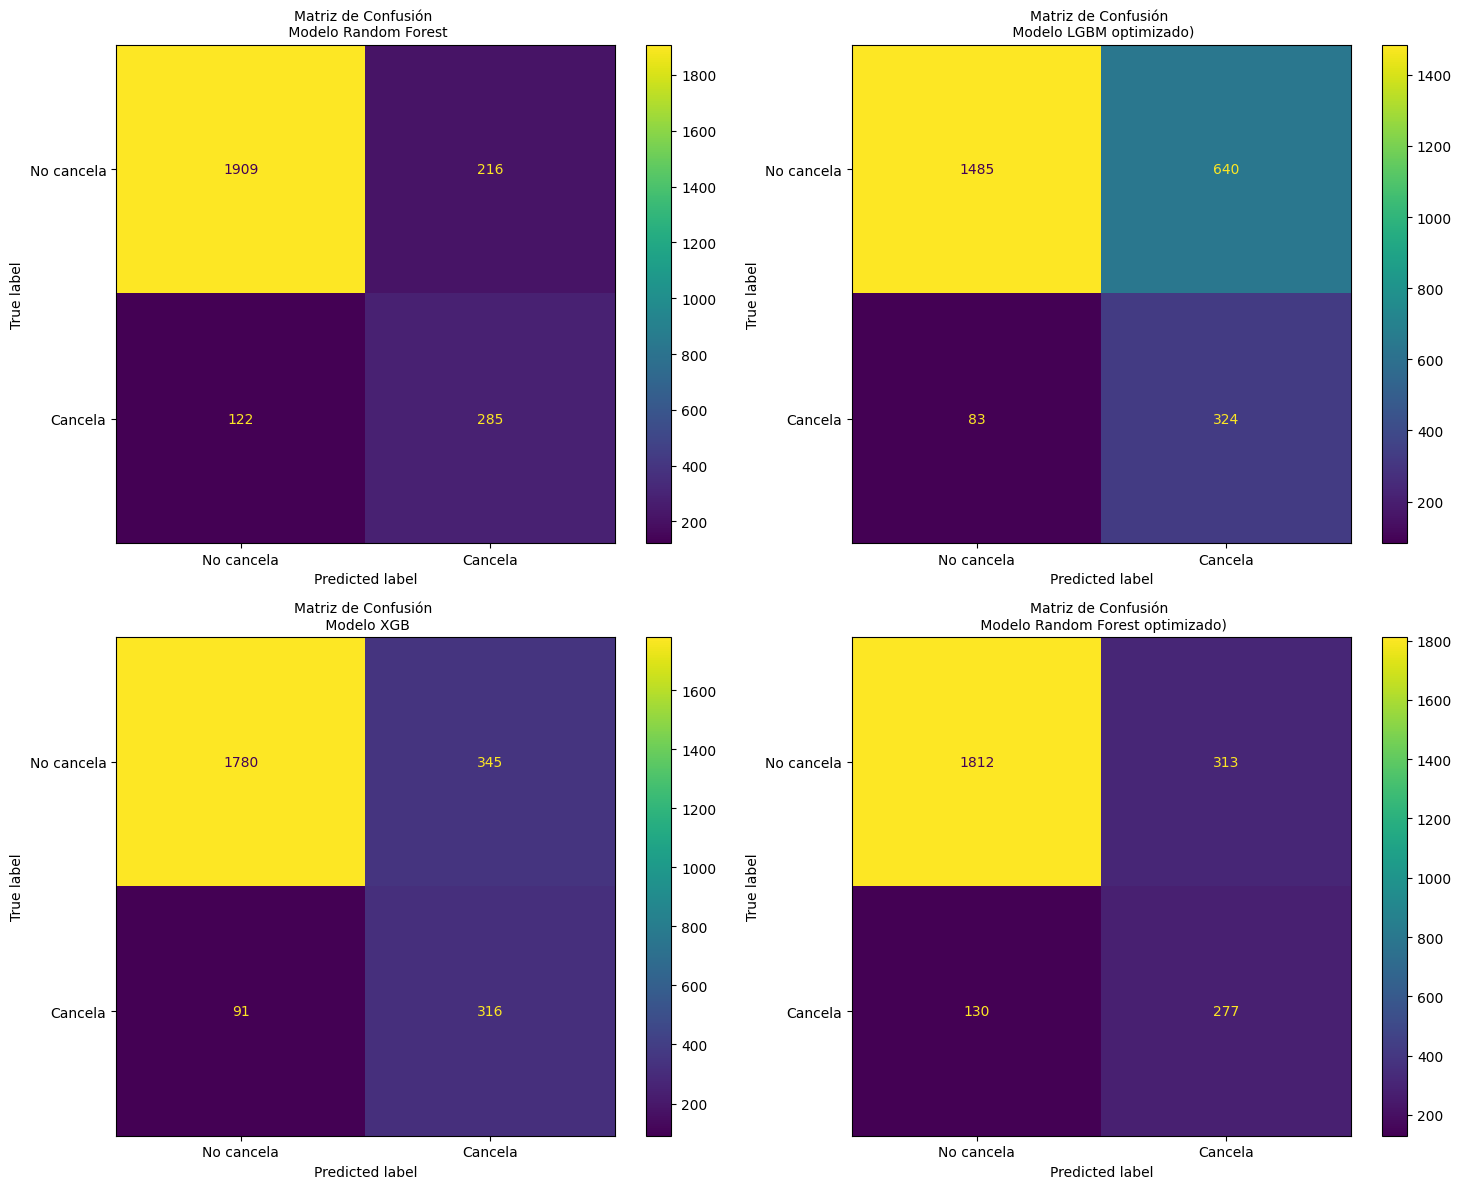

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(15, 12)) # Crear una figura con 2 filas y 2 columnas de ejes

display_labels = ['No cancela', 'Cancela']

ConfusionMatrixDisplay.from_estimator(modelo_rdm_forest, X_test, y_test, ax=axs[0, 0], display_labels=display_labels) # Pasar el primer eje a la función
axs[0, 0].set_title('Matriz de Confusión \n Modelo Random Forest', fontsize=10) # Título para el primer subplot

ConfusionMatrixDisplay.from_estimator(modelo_lgbm_optimizado, X_test, y_test, ax=axs[0, 1], display_labels=display_labels) # Pasar el segundo eje a la función
axs[0, 1].set_title('Matriz de Confusión \n Modelo LGBM optimizado)', fontsize=10) # Título para el segundo subplot

ConfusionMatrixDisplay.from_estimator(modelo_xgb_optimizado, X_test, y_test, ax=axs[1, 0], display_labels=display_labels) # Pasar el tercer eje a la función
axs[1, 0].set_title('Matriz de Confusión \n Modelo XGB', fontsize=10) # Título para el tercer subplot

ConfusionMatrixDisplay.from_estimator(modelo_rf_smote_optimizado, X_test, y_test, ax=axs[1, 1], display_labels=display_labels) # Pasar el cuarto eje a la función
axs[1, 1].set_title('Matriz de Confusión \n Modelo Random Forest optimizado)', fontsize=10) # Título para el cuarto subplot


plt.tight_layout() # Ajustar el diseño para evitar superposiciones
plt.show() # Mostrar el gráfico

In [ ]:
import pickle
import pandas as pd

# Cargar el modelo champion1 desde el archivo pkl
try:
  with open('modelo_champion1.pkl', 'rb') as file:
    model_champion = pickle.load(file)
  print('Modelo champion cargado con éxito.')
except Exception as e:
  print(f'Error al cargar el modelo: {e}')

def filtrar_clientes_por_probabilidad(model, data_frame, probabilidad_objetivo):
    """
    Filtra el DataFrame de clientes para identificar aquellos con una probabilidad de cancelación
    superior a la especificada, utilizando el modelo proporcionado.

    Args:
        model: El modelo entrenado (e.g., modelo_lgbm_optimizado) que tiene un método predict_proba.
        data_frame (pd.DataFrame): El DataFrame completo de clientes, incluyendo la columna 'Attrition_Flag'.
        probabilidad_objetivo (float): El umbral de probabilidad para considerar a un cliente como de alto riesgo.

    Returns:
        pd.DataFrame: Un DataFrame que contiene a los clientes cuya probabilidad de cancelación
                      supera el umbral especificado, con una columna adicional 'Prob_Cancel'.
    """
    # 1. Asegurar que las características de entrada coincidan con las de entrenamiento
    # Usamos X_train.columns para obtener las columnas correctas.
    df_features_for_prediction = data_frame[X_train.columns]

    # 2. Determinar la probabilidad de cancelación
    prob_cancel_raw = model.predict_proba(df_features_for_prediction)

    # 3. Extraer probabilidad de Cancelaciones (Attrition_Flag = 1) y añadirla al DataFrame original
    # Usamos .copy() para evitar SettingWithCopyWarning en operaciones subsiguientes
    df_con_prob = data_frame.copy()
    df_con_prob['Prob_Cancel'] = prob_cancel_raw[:, 1]

    # 4. Filtrar clientes de alto riesgo
    df_alto_riesgo = df_con_prob[df_con_prob['Prob_Cancel'] > probabilidad_objetivo]

    return df_alto_riesgo

print("Función 'filtrar_clientes_por_probabilidad' definida correctamente.")

# Ejemplo de uso de la función con un umbral y el modelo cargado
if 'model_champion' in locals():
    umbral_ejemplo = 0.5  # Puedes cambiar este umbral
    df_alto_riesgo_ejemplo = filtrar_clientes_por_probabilidad(model_champion, df, umbral_ejemplo)
    print(f"\nClientes de alto riesgo (probabilidad > {umbral_ejemplo:.2f}):")
    if not df_alto_riesgo_ejemplo.empty:
        display(df_alto_riesgo_ejemplo.head())
        print(f"Total de clientes de alto riesgo: {len(df_alto_riesgo_ejemplo)}")
    else:
        print("No se encontraron clientes de alto riesgo con el umbral especificado.")
else:
    print("El modelo no ha sido cargado. No se puede ejecutar el ejemplo de filtrado.")

Modelo champion cargado con éxito.
Función 'filtrar_clientes_por_probabilidad' definida correctamente.

Clientes de alto riesgo (probabilidad > 0.50):


,Attrition_Flag,Customer_Age,Months_Inactive_12_mon,Contacts_Count_12_mon,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Low_Relationship_Count,Gender_M,Card_Category_Gold,Card_Category_Platinum,Card_Category_Silver,Prob_Cancel
2,0,51,1,0,2.333,0.000,0,1,0,0,0,0.500475
4,0,40,1,0,2.500,0.000,0,1,0,0,0,0.500475
12,0,56,6,0,3.250,0.000,1,1,0,0,0,0.503623
21,1,62,3,3,0.600,0.000,1,0,0,0,0,0.530688
23,0,47,3,2,0.353,0.626,1,0,0,0,0,0.538860


Total de clientes de alto riesgo: 3954


In [ ]:
try:
  with open('modelo_champion1.pkl', 'rb') as file:
    model_champion = pickle.load(file)
  print('Modelo champion cargado con éxito.')
except Exception as e:
  print(f'Error al cargar el modelo: {e}')

filtrar_clientes_por_probabilidad(model_champion, df, 0.5)

Modelo champion cargado con éxito.


,Attrition_Flag,Customer_Age,Months_Inactive_12_mon,Contacts_Count_12_mon,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Low_Relationship_Count,Gender_M,Card_Category_Gold,Card_Category_Platinum,Card_Category_Silver,Prob_Cancel
2,0,51,1,0,2.333,0.000,0,1,0,0,0,0.500475
4,0,40,1,0,2.500,0.000,0,1,0,0,0,0.500475
12,0,56,6,0,3.250,0.000,1,1,0,0,0,0.503623
21,1,62,3,3,0.600,0.000,1,0,0,0,0,0.530688
23,0,47,3,2,0.353,0.626,1,0,0,0,0,0.538860
...,...,...,...,...,...,...,...,...,...,...,...,...
10112,1,33,1,4,0.622,0.000,1,1,1,0,0,0.527550
10114,0,29,1,5,0.655,0.000,1,1,0,0,0,0.527550
10119,1,55,3,3,0.514,0.172,0,0,0,0,0,0.522471
10124,1,44,3,4,0.818,0.000,0,0,0,0,0,0.530688


## Resumen

El objetivo principal de este notebook es desarrollar y evaluar modelos de Machine Learning para predecir el abandono de clientes (churn). Se busca identificar a los clientes con alta probabilidad de cancelar sus servicios y comprender los factores que influyen en esta decisión, permitiendo a la organización implementar estrategias de retención proactivas. Se exploran diferentes modelos, se optimizan y se utilizan para identificar clientes de alto riesgo y analizar sus motivos de cancelación.

## Pasos del Preprocesamiento de Datos

El proceso de preprocesamiento de datos se inició con la carga del conjunto de datos `dataset_churn_procesado_para_ml.csv`. Este archivo, que ya contenía datos preprocesados para modelado de machine learning, fue cargado en un DataFrame de pandas llamado `df`. La ruta del archivo se almacenó en la variable `datos_url` y luego se utilizó `pd.read_csv()` para realizar la carga.

Una vez cargado el `DataFrame`, se realizaron exploraciones iniciales para comprender su estructura y contenido. La función `df.head()` se utilizó para visualizar las primeras filas del conjunto de datos, permitiendo una rápida inspección de las características y los tipos de valores presentes. Posteriormente, `df.info()` proporcionó un resumen conciso del DataFrame, incluyendo el número de entradas, la cantidad de columnas, los tipos de datos de cada columna y, crucialmente, la identificación de posibles valores nulos en cada característica, asegurando que el dataset estaba limpio de valores faltantes antes de continuar con el análisis.

Para comprender las relaciones entre las diferentes variables del conjunto de datos, se procedió a realizar un análisis de correlación. Primero, se creó una copia del DataFrame original (`df`) llamada `datos_corr`. Luego, se calculó la matriz de correlación utilizando el método `.corr()` de pandas. Para una visualización clara y rápida de estas correlaciones, se generó un mapa de calor (`sns.heatmap`) utilizando la biblioteca `seaborn`. Este mapa de calor mostró los coeficientes de correlación entre todas las parejas de variables, indicando la fuerza y dirección de su relación.

Los hallazgos clave del análisis de correlación, centrados en la variable objetivo `Attrition_Flag`, revelaron lo siguiente:

*   **Total_Ct_Chng_Q4_Q1 (-0.29):** Esta variable muestra una correlación negativa moderada, sugiriendo que un menor cambio en el total de contactos entre los trimestres Q4 y Q1 se asocia con una mayor tasa de abandono de clientes.
*   **Contacts_Count_12_mon (0.20):** Presenta una correlación positiva débil, indicando que un mayor número de contactos en los últimos 12 meses está relacionado con una mayor probabilidad de abandono.
*   **Avg_Utilization_Ratio (0.18):** También con una correlación positiva débil, sugiere que un mayor promedio de la tasa de utilización de la tarjeta se relaciona con una mayor tasa de abandono.
*   **Months_Inactive_12_mon (0.15):** Con una correlación positiva débil, indica que un mayor número de meses inactivos en los últimos 12 meses está relacionado con una mayor tasa de abandono.

## Modelado y Evaluación


## Detallar Modelado y Evaluación

### 1. Preparación de Datos

Para el modelado, la variable objetivo `Attrition_Flag` fue separada del conjunto de datos y renombrada a `Canceled_Yes` (`y`), mientras que el resto de las columnas se designaron como variables predictoras (`X`). Posteriormente, `X` y `y` se dividieron en conjuntos de entrenamiento y prueba utilizando `train_test_split`. Se asignó el 75% de los datos al entrenamiento y el 25% a la prueba (`X_train`, `X_test`, `y_train`, `y_test`), asegurando la **estratificación** por la variable objetivo (`y`) para mantener la proporción de clases en ambos conjuntos. Esto es crucial debido al desequilibrio de clases presente en los datos.

### 2. Modelo Baseline (DummyClassifier)

El `DummyClassifier` se utilizó como un **modelo baseline** para establecer un punto de referencia mínimo de rendimiento. Se entrenó con la estrategia `'most_frequent'`, lo que significa que siempre predice la clase predominante en el conjunto de entrenamiento (en este caso, la clase `0` o no abandono).

**Rendimiento:**
- **Accuracy:** El modelo baseline mostró un accuracy del **83.93%**. Esta métrica es engañosa en conjuntos de datos desequilibrados, ya que el modelo simplemente predice la clase mayoritaria correctamente.
- **Matriz de Confusión:** La matriz de confusión confirmó que el modelo predijo todas las instancias como clase `0`. Esto significa que todos los clientes que realmente abandonaron (clase `1`) fueron clasificados incorrectamente como no-abandono (falsos negativos).
- **Reporte de Clasificación:** El reporte detalló que la precisión, el recall y el F1-Score para la clase `1` (abandono) fueron **0.00**, indicando que el modelo no pudo identificar a ningún cliente que iba a abandonar. Aunque la precisión para la clase `0` fue alta, la incapacidad de detectar la clase de interés hace que este modelo sea inútil para el objetivo de predecir el abandono.

### 3. Modelo Random Forest Inicial

Se inicializó y entrenó un `RandomForestClassifier` para abordar el problema de clasificación, prestando especial atención al desequilibrio de clases presente en los datos. Para ello, se configuró `class_weight='balanced'`, lo que ajusta automáticamente los pesos de las clases inversamente proporcionales a sus frecuencias en los datos de entrada, dando más importancia a la clase minoritaria (abandono).

Los parámetros iniciales del modelo fueron:
- `max_depth=10`: Limita la profundidad máxima de cada árbol en el bosque para evitar el sobreajuste.
- `min_samples_leaf=2`: El número mínimo de muestras requeridas para estar en un nodo hoja.
- `min_samples_split=5`: El número mínimo de muestras requeridas para dividir un nodo interno.
- `n_estimators=200`: El número de árboles en el bosque.
- `random_state=58`: Para asegurar la reproducibilidad de los resultados.

**Rendimiento:**
- **Accuracy:** El modelo Random Forest inicial logró un accuracy del **86.65%**, lo cual representa una mejora significativa sobre el modelo baseline.
- **Matriz de Confusión:** La matriz de confusión mostró una capacidad mucho mejor para identificar a los clientes que realmente abandonan (clase `1`) en comparación con el modelo baseline.
- **Reporte de Clasificación:**
    - Para la clase `0` (no abandono): Obtuvo una precisión del **94%** y un recall del **90%**, lo que indica que identifica correctamente a la mayoría de los clientes que no abandonan con alta fiabilidad.
    - Para la clase `1` (abandono): Presentó un **recall del 70%** y una precisión del **57%**. Esto significa que el modelo es capaz de detectar 7 de cada 10 clientes que van a abandonar, lo cual es un avance crucial respecto al modelo baseline. Aunque la precisión para la clase 1 aún tiene margen de mejora, este modelo es considerablemente más útil para la detección temprana de clientes en riesgo de abandono.

### 4. Optimización del Modelo Random Forest con SMOTE y GridSearchCV

Para mejorar la capacidad del modelo Random Forest para detectar la clase minoritaria (abandono), se aplicó una estrategia de **sobremuestreo (Oversampling)** de la clase minoritaria utilizando SMOTE (Synthetic Minority Over-sampling Technique) y se realizó una **optimización de hiperparámetros** con GridSearchCV.

#### Aplicación de SMOTE:
- **`smote = SMOTE(random_state=58)`**: Se inicializó SMOTE para generar nuevas muestras sintéticas de la clase minoritaria (`1`).
- **`X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)`**: SMOTE se aplicó únicamente al conjunto de entrenamiento. Antes de SMOTE, la distribución de clases en `y_train` era significativamente desequilibrada (6375 para la clase `0` y 1220 para la clase `1`). Después de aplicar SMOTE, `y_train_smote` mostró un balance perfecto de clases (6375 para la clase `0` y 6375 para la clase `1`), eliminando el sesgo hacia la clase mayoritaria.

#### Optimización con GridSearchCV:
- Se configuró `GridSearchCV` para buscar los mejores hiperparámetros del `RandomForestClassifier` utilizando los datos de entrenamiento balanceados por SMOTE (`X_train_smote`, `y_train_smote`).
- **`param_grid_rf_smote`**: El espacio de búsqueda de parámetros incluyó:
    - `'n_estimators'`: [300, 500]
    - `'max_depth'`: [30]
    - `'min_samples_leaf'`: [1]
    - `'min_samples_split'`: [1, 2]
- **`scoring='recall'`**: Se estableció el recall como la métrica principal de optimización para asegurar que el modelo priorizara la correcta identificación de la clase minoritaria (abandono).
- **`cv=5`**: Se utilizó validación cruzada de 5 pliegues para una evaluación robusta de cada combinación de parámetros.
- Los **mejores parámetros encontrados** fueron: `{'max_depth': 30, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 500}`.
- El **mejor recall (clase minoritaria)** en validación cruzada fue de **0.8711**.

#### Evaluación del Modelo Random Forest Optimizado con SMOTE:
El `modelo_rf_smote_optimizado` (el mejor estimador obtenido de GridSearchCV) se evaluó en el conjunto de prueba original (`X_test`, `y_test`), que no fue afectado por SMOTE, para obtener una estimación imparcial de su rendimiento.

- **Accuracy: 0.8250**
- **Precision (Clase 1): 0.4695**
- **Recall (Clase 1): 0.6806**
- **F1-Score (Clase 1): 0.5557**
- **AUC: 0.8398**

**Reporte de Clasificación (RandomForest Optimizado con SMOTE):**
- Para la clase `0` (no abandono): Precisión del **93%** y recall del **85%**.
- Para la clase `1` (abandono): Precisión del **47%** y recall del **68%**.

La optimización con SMOTE y GridSearchCV logró un recall similar para la clase 1 (68%) en comparación con el modelo Random Forest inicial (70%), pero con una ligera disminución en precisión para la clase 1 y accuracy general. Esto indica un compromiso entre la identificación de la clase minoritaria y la precisión general, siendo el recall una métrica clave para la detección de abandono. El valor de AUC (0.8398) es bueno, indicando una buena capacidad del modelo para distinguir entre las clases.

### 5. Modelo LightGBM Inicial

Se inicializó y entrenó un `LGBMClassifier` (Light Gradient Boosting Machine) con `class_weight='balanced'` para manejar el desequilibrio de clases, similar al Random Forest. El `random_state=58` se utilizó para asegurar la reproducibilidad.

**Rendimiento:**
- **Accuracy:** El modelo LightGBM inicial obtuvo un accuracy del **84.79%**.
- **Matriz de Confusión:** La matriz de confusión mostró una capacidad razonable para identificar la clase de abandono.
- **Reporte de Clasificación:**
    - Para la clase `0` (no abandono): Precisión del **95%** y recall del **87%**.
    - Para la clase `1` (abandono): Presentó un **recall del 74%** y una precisión del **52%**. Esto significa que el modelo LightGBM inicial fue ligeramente mejor en la detección de la clase de abandono (recall del 74% vs 70% del Random Forest inicial) pero con una precisión un poco menor (52% vs 57%). Esto lo convierte en un fuerte candidato para la detección temprana de clientes en riesgo.

### 6. Optimización del Modelo LightGBM con GridSearchCV

Para optimizar el rendimiento del `LGBMClassifier` en la detección de la clase minoritaria (abandono), se aplicó `GridSearchCV` al modelo con los datos de entrenamiento originales.

#### Optimización con GridSearchCV:
- Se configuró `GridSearchCV` para buscar los mejores hiperparámetros para el `LGBMClassifier` utilizando el conjunto de entrenamiento original (`X_train`, `y_train`).
- **`param_grid`**: El espacio de búsqueda de parámetros incluyó:
    - `'n_estimators'`: [25, 50, 100]
    - `'learning_rate'`: [0.001, 0.005]
    - `'num_leaves'`: [5, 10]
    - `'max_depth'`: [10, 15]
    - `'min_child_samples'`: [3, 5, 10]
    - `'subsample'`: [0.05, 0.2]
- **`scoring='recall'`**: Similar al Random Forest, se priorizó el recall para maximizar la detección de la clase minoritaria.
- **`cv=3`**: Se utilizó validación cruzada de 3 pliegues.
- Los **mejores parámetros encontrados** fueron: `{'learning_rate': 0.005, 'max_depth': 10, 'min_child_samples': 3, 'n_estimators': 50, 'num_leaves': 5, 'subsample': 0.05}`.
- El **mejor recall (clase minoritaria)** en validación cruzada fue de **0.7893**.

#### Evaluación del Modelo LightGBM Optimizado:
El `modelo_lgbm_optimizado` (el mejor estimador de `GridSearchCV`) se evaluó en el conjunto de prueba (`X_test`, `y_test`).

- **Accuracy: 0.7145**
- **Precision (Clase 1): 0.3361**
- **Recall (Clase 1): 0.7961**
- **F1-Score (Clase 1): 0.4726**
- **AUC: 0.8241**

**Reporte de Clasificación (LightGBM Optimizado):**
- Para la clase `0` (no abandono): Precisión del **95%** y recall del **70%**.
- Para la clase `1` (abandono): Precisión del **34%** y recall del **80%**.

La optimización del LightGBM resultó en el mayor recall para la clase 1 de todos los modelos (80%), lo que indica una excelente capacidad para identificar a los clientes que abandonarán. Sin embargo, esto vino acompañado de una reducción significativa en la precisión para la clase 1 (34%) y en el accuracy general (71.45%) en comparación con el LightGBM inicial y los modelos Random Forest. Esto sugiere que el modelo optimizado es muy bueno para encontrar a la mayoría de los que abandonan, pero a costa de clasificar erróneamente a muchos clientes que no abandonarían como si lo hicieran (falsos positivos). El AUC de 0.8241 sigue siendo respetable, pero el bajo F1-Score para la clase 1 resalta el compromiso entre precisión y recall para esta clase.


### 6. Optimización del Modelo LightGBM con GridSearchCV

Para optimizar el rendimiento del `LGBMClassifier` en la detección de la clase minoritaria (abandono), se aplicó `GridSearchCV` al modelo con los datos de entrenamiento originales.

#### Optimización con GridSearchCV:
- Se configuró `GridSearchCV` para buscar los mejores hiperparámetros para el `LGBMClassifier` utilizando el conjunto de entrenamiento original (`X_train`, `y_train`).
- **`param_grid`**: El espacio de búsqueda de parámetros incluyó:
    - `'n_estimators'`: [25, 50, 100]
    - `'learning_rate'`: [0.001, 0.005]
    - `'num_leaves'`: [5, 10]
    - `'max_depth'`: [10, 15]
    - `'min_child_samples'`: [3, 5, 10]
    - `'subsample'`: [0.05, 0.2]
- **`scoring='recall'`**: Similar al Random Forest, se priorizó el recall para maximizar la detección de la clase minoritaria.
- **`cv=3`**: Se utilizó validación cruzada de 3 pliegues.
- Los **mejores parámetros encontrados** fueron: `{'learning_rate': 0.005, 'max_depth': 10, 'min_child_samples': 3, 'n_estimators': 50, 'num_leaves': 5, 'subsample': 0.05}`.
- El **mejor recall (clase minoritaria)** en validación cruzada fue de **0.7893**.

#### Evaluación del Modelo LightGBM Optimizado:
El `modelo_lgbm_optimizado` (el mejor estimador de `GridSearchCV`) se evaluó en el conjunto de prueba (`X_test`, `y_test`).

- **Accuracy: 0.7145**
- **Precision (Clase 1): 0.3361**
- **Recall (Clase 1): 0.7961**
- **F1-Score (Clase 1): 0.4726**
- **AUC: 0.8241**

**Reporte de Clasificación (LightGBM Optimizado):**
- Para la clase `0` (no abandono): Precisión del **95%** y recall del **70%**.
- Para la clase `1` (abandono): Precisión del **34%** y recall del **80%**.

La optimización del LightGBM resultó en el mayor recall para la clase 1 de todos los modelos (80%), lo que indica una excelente capacidad para identificar a los clientes que abandonarán. Sin embargo, esto vino acompañado de una reducción significativa en la precisión para la clase 1 (34%) y en el accuracy general (71.45%) en comparación con el LightGBM inicial y los modelos Random Forest. Esto sugiere que el modelo optimizado es muy bueno para encontrar a la mayoría de los que abandonan, pero a costa de clasificar erróneamente a muchos clientes que no abandonarían como si lo hicieran (falsos positivos). El AUC de 0.8241 sigue siendo respetable, pero el bajo F1-Score para la clase 1 resalta el compromiso entre precisión y recall para esta clase.


### 7. Comparación de Modelos

Para una evaluación completa y una selección informada del modelo campeón, se recopilaron las métricas clave (Accuracy, Precision, Recall, F1-Score y AUC) para todos los modelos desarrollados:

- **DummyClassifier (Baseline)**
- **RandomForestClassifier (Inicial)**
- **Optimized RandomForestClassifier (con SMOTE y GridSearchCV)**
- **LGBMClassifier (Inicial)**
- **Optimized LGBMClassifier (con GridSearchCV)**

Todas estas métricas fueron consolidadas en un DataFrame (`df_resumen`) para facilitar una comparación directa y visual de su rendimiento. Esta tabla permite identificar rápidamente las fortalezas y debilidades de cada modelo, especialmente en relación con la detección de la clase minoritaria (abandono), que es el objetivo principal de este proyecto.

El análisis de este resumen de métricas es crucial para determinar qué modelo ofrece el mejor equilibrio entre la capacidad de identificar clientes en riesgo de abandono (recall) y la minimización de falsos positivos (precision), en funci\u00f3n de los objetivos de negocio.

### 7. Comparación de Modelos

Para una evaluación completa y una selección informada del modelo campeón, se recopilaron las métricas clave (Accuracy, Precision, Recall, F1-Score y AUC) para todos los modelos desarrollados:

- **DummyClassifier (Baseline)**
- **RandomForestClassifier (Inicial)**
- **Optimized RandomForestClassifier (con SMOTE y GridSearchCV)**
- **LGBMClassifier (Inicial)**
- **Optimized LGBMClassifier (con GridSearchCV)**

Todas estas métricas fueron consolidadas en un DataFrame (`df_resumen`) para facilitar una comparación directa y visual de su rendimiento. Esta tabla permite identificar rápidamente las fortalezas y debilidades de cada modelo, especialmente en relación con la detección de la clase minoritaria (abandono), que es el objetivo principal de este proyecto.

El análisis de este resumen de métricas es crucial para determinar qué modelo ofrece el mejor equilibrio entre la capacidad de identificar clientes en riesgo de abandono (recall) y la minimización de falsos positivos (precision), en función de los objetivos de negocio.

## Selección de Modelos y Aplicación


### Selección de Modelos Champion y Aplicación

Para la selección de los modelos 'campeones' (`champion models`), se realizó un análisis comparativo de las métricas de rendimiento obtenidas de los diferentes modelos entrenados, tal como se muestra en el `df_resumen`:

```
                                  Accuracy  Precision (Clase 1)  \
DummyClassifier                   0.839258             0.000000   
RandomForestClassifier            0.866509             0.568862   
Optimized RandomForestClassifier  0.825039             0.469492   
LightGBM Classifier               0.847946             0.518836   
Optimized LightGBM Classifier     0.714455             0.336100   

                                  Recall (Clase 1)  F1-Score (Clase 1)       AUC  
DummyClassifier                           0.000000            0.000000  0.500000  
RandomForestClassifier                    0.700246            0.627753  0.879055  
Optimized RandomForestClassifier          0.680590            0.555667  0.839807  
LightGBM Classifier                       0.741989            0.612450  0.880491  
Optimized LightGBM Classifier             0.796069            0.472648  0.824116  
```

La prioridad principal en este caso es identificar a los clientes que **realmente van a abandonar** (clase 1), lo que se refleja en la métrica **Recall (Clase 1)**. Un alto recall es crucial para no perder la oportunidad de intervenir y retener a estos clientes. Sin embargo, también es importante mantener una precisión razonable para evitar intervenciones innecesarias en clientes que no tenían intención de abandonar.

Basándonos en este criterio, se seleccionaron los siguientes dos modelos como 'campeones':

1.  **`Optimized LightGBM Classifier` (`modelo_lgbm_optimizado`)**: Este modelo fue elegido debido a que presenta el **recall más alto (0.796)** para la clase 1 entre todos los modelos. Esto significa que es el modelo que mejor detecta a los clientes que van a abandonar, identificando aproximadamente a 8 de cada 10 clientes en riesgo. Aunque su precisión (0.336) y F1-Score (0.472) son más bajos, su capacidad superior para **capturar la mayoría de los positivos reales** lo hace invaluable para una estrategia de retención.

2.  **`RandomForestClassifier` (`modelo_rdm_forest`)**: Este modelo se seleccionó porque ofrece un buen balance entre **recall (0.700)** y **precisión (0.569)** para la clase 1, resultando en un F1-Score de 0.628. Además, su AUC es el más alto (0.879). Aunque su recall es ligeramente inferior al LightGBM optimizado, su mayor precisión y F1-Score sugieren que realiza una buena identificación de la clase 1 sin generar tantos falsos positivos, lo que podría ser útil en escenarios donde los recursos para la intervención son limitados y se busca un equilibrio entre identificar clientes en riesgo y la eficiencia de la intervención.

### Aplicación para Identificación de Clientes de Alto Riesgo

El `modelo_lgbm_optimizado` fue el modelo principal utilizado para calcular la probabilidad de abandono para todos los clientes. Se aplicó la función `predict_proba()` de este modelo al `DataFrame` completo de características de los clientes (`df_features`), excluyendo la variable objetivo `Attrition_Flag`.

La salida de `predict_proba()` produce las probabilidades para ambas clases (no abandono y abandono). La probabilidad de abandono (clase 1) se extrajo y se guardó en una nueva columna llamada `Prob_Cancel` dentro del `DataFrame` original `df`. Esta columna es fundamental ya que proporciona una puntuación de riesgo para cada cliente.

La columna `Prob_Cancel` es esencial para:
*   **Identificación masiva de clientes de alto riesgo**: Permite filtrar clientes que superan un umbral de probabilidad de abandono definido, utilizando la función `analisis_gral_alto_riesgo`.
*   **Análisis detallado por ID de cliente**: Facilita la función `motivos_cancel` al proporcionar la probabilidad base de abandono, la cual se utiliza para determinar si se debe proceder con un análisis más profundo de las razones de riesgo para un cliente individual.

## Funciones de Análisis Interactivo



### Funciones de Análisis Interactivo

### Búsqueda Masiva de Clientes de Alto Riesgo

La función `analisis_gral_alto_riesgo` está diseñada para identificar de manera masiva clientes con una probabilidad de abandono superior a un umbral definido. Esta función se integra con un widget interactivo `FloatText` (`input_prob`) que permite al usuario establecer dinámicamente la `probabilidad_objetivo` (probabilidad de churn) de interés. Una vez que se ingresa el umbral deseado, el usuario puede presionar el botón 'Filtrar Clientes de Alto Riesgo' (`button_filtro`) para ejecutar la función y mostrar una lista de todos los clientes que superan dicho umbral. Esto permite una rápida identificación de segmentos de clientes potencialmente en riesgo para intervenciones proactivas.

### Análisis Individual de Clientes

La función `motivos_cancel` permite realizar un análisis detallado para un cliente específico, dado su `id_cliente`. Esta función utiliza el modelo campeón 'Random Forest' (`modelo_rdm_forest`) para predecir la probabilidad de abandono del cliente. Si la probabilidad de abandono supera un umbral (actualmente fijado en 0.5 para generar la explicación), la función procede a identificar las razones potenciales de abandono.

Para proporcionar una explicación clara, `motivos_cancel` rastrea el camino de decisión del cliente a través de un árbol representativo del modelo Random Forest. Para cada característica crítica identificada en este camino, compara el valor del cliente con un rango de referencia (Intervalo de Confianza) de los clientes que históricamente han abandonado. La función muestra si el valor del cliente cae dentro de este rango de referencia, lo que ayuda a entender si el comportamiento actual del cliente en esa característica es similar al de los clientes que cancelaron.

El nivel de confianza para estos rangos de referencia es completamente personalizable a través de un widget interactivo `FloatText` llamado `input_nivel_confianza`. El análisis para un cliente individual se activa mediante un `IntText` (`Input_ID_Cliente`) para ingresar el ID del cliente y un botón 'Buscar Cliente' (`Button_Buscar`) que ejecuta la función `motivos_cancel`.

## Resumen
* Objetivo del Proyecto: El objetivo principal del proyecto es desarrollar y evaluar modelos de Machine Learning para la predicción de fuga de clientes (churn), identificar clientes con alta probabilidad de abandono, comprender los factores influyentes y permitir estrategias de retención proactivas.

* Preprocesamiento de Datos: Los datos se cargaron desde dataset_churn_procesado_para_ml.csv y se sometieron a una exploración inicial (df.head(), df.info()), confirmando la ausencia de valores faltantes. El análisis de correlación destacó variables clave relacionadas con Attrition_Flag:  
  * Total_Ct_Chng_Q4_Q1 (correlación negativa de -0.29),
  * Contacts_Count_12_mon (positiva, 0.20),
  * Avg_Utilization_Ratio (positiva, 0.18)  
  * Months_Inactive_12_mon (positiva, 0.15).

* Modelado y Evaluación de Machine Learning: El conjunto de datos se dividió en entrenamiento y prueba (75%/25%) con estratificación para la variable objetivo (Attrition_Flag / Canceled_Yes).

  * Modelo Base (DummyClassifier): Arrojó una precisión (accuracy) del 83.93%, pero no logró identificar a ningún cliente en fuga (recall de 0.00 para churn), lo que subraya la necesidad de modelos más sofisticados debido al desequilibrio de clases.

  * Random Forest Inicial: Logró un 86.65% de precisión, con un recall del 70% y una precisión del 57% para la clase de fuga, demostrando una mejora significativa.

  * Random Forest Optimizado (SMOTE + GridSearchCV): Tras aplicar SMOTE para equilibrar los datos de entrenamiento y optimizar el recall mediante GridSearchCV, el modelo alcanzó un 82.50% de precisión, 68.06% de recall, 46.95% de precisión para churn y un AUC de 0.8398.

  * LightGBM Inicial: Mostró un 84.79% de precisión, con un 74% de recall y 52% de precisión para churn, superando ligeramente al Random Forest inicial en recall.

  * LightGBM Optimizado (GridSearchCV): Priorizando el recall, este modelo alcanzó el recall más alto para fuga con un 79.61% (con 71.45% de precisión general y 33.61% de precisión para la clase churn), y un AUC de 0.8241, indicando una fuerte capacidad para detectar clientes en fuga a costa de un mayor número de falsos positivos.

* Selección del Modelo Ganador (Champion):

Se seleccionó el LightGBM Optimizado como modelo ganador debido a su mayor recall (0.796) para la clase de fuga, lo que lo hace más efectivo para identificar clientes potenciales a abandonar.

También se seleccionó el Random Forest Inicial por su sólido equilibrio entre recall (0.700) y precisión (0.569) para churn, junto con el AUC más alto (0.879), siendo adecuado para escenarios donde es necesario gestionar los falsos positivos.

Aplicación para Probabilidad de Fuga e Identificación de Alto Riesgo: El modelo_lgbm_optimizado se utilizó principalmente para calcular Prob_Cancel (probabilidad de fuga) para todos los clientes, lo que sirve como una puntuación de riesgo crítica para análisis posteriores.

* Herramientas Interactivas:

Una función interactiva analisis_gral_alto_riesgo permite a los usuarios filtrar clientes de alto riesgo estableciendo dinámicamente un umbral de probabilidad de fuga.

Una función de análisis individual motivos_cancel utiliza el modelo Random Forest para predecir la probabilidad de fuga de un cliente específico, identifica los motivos del abandono mediante el rastreo de rutas de decisión y compara los valores del cliente con los rangos de referencia de clientes que abandonaron históricamente. Esta función admite niveles de confianza personalizables.

* Conclusiones y Próximos Pasos: El proyecto desarrolló con éxito múltiples modelos para abordar el problema del desequilibrio en la predicción de fuga, observándose un compromiso claro entre maximizar el recall (LightGBM Optimizado) y lograr un equilibrio entre precisión y recall (Random Forest Inicial). Esto proporciona flexibilidad dependiendo del costo comercial asociado a los falsos positivos frente a los falsos negativos.

Las herramientas de análisis interactivo para obtener información masiva e individual de los clientes son fundamentales para la operatividad de los modelos. El desarrollo futuro podría incluir la integración de estas herramientas en un tablero (dashboard) intuitivo para que los usuarios de negocio identifiquen y analicen directamente a los clientes en riesgo, y prueben diferentes estrategias de intervención basadas en los motivos de fuga identificados.

# Task
Utilize the interactive widgets to filter and display customers with a high churn probability using the loaded champion model, and to analyze individual customer churn motives.